In [7]:
import pathlib
import sys
import os
import numpy as np

# Hacky way to get to root package
if "notebooks" in os.getcwd():
    os.chdir("..")

In [8]:
%load_ext autoreload
%autoreload 2
    
import sys
from data_container import load_scouted_data
import pandas as pd
import plotly.express as px
pd.set_option('display.max_columns', None)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
scouted_data = load_scouted_data()

scouted_data['Team and Robot'] = scouted_data['Team and Robot'].astype(str)
scouted_data

,Scouter Initials,Match Number,Team and Robot,No Show,autoCarrotO,autoCarrotCakeO,autoCarrotL1,autoCarrotL2,autoCarrotL3,autoCarrotCakeL1,autoCarrotCakeL2,autoCarrotCakeL3,telCarrotO,telCarrotCakeO,telCarrotL1,telCarrotL2,telCarrotL3,telCarrotCakeL1,telCarrotCakeL2,telCarrotCakeL3,Auto Cross Kitchen Line,Auto Robot Stuck or Astop in Auto?,Harvest Haul Carrots,Harvest Haul Carrot Cakes,XXXXXX
0,abc,1,340,True,0,0,1,4,0,1,1,0,28,14,28,27,22,12,6,3,False,False,2,1,NaN
1,abc,1,3504,False,0,0,1,0,2,1,0,1,22,6,19,4,23,16,20,15,False,False,0,0,NaN
2,abc,1,3015,False,4,2,1,2,0,0,1,0,10,19,23,12,30,12,16,12,False,False,1,1,NaN
3,abc,1,2641,False,2,0,1,3,4,2,1,2,4,10,3,18,26,15,10,7,False,False,0,0,NaN
4,abc,1,3990,False,3,1,3,1,1,0,2,2,2,4,13,1,29,0,19,7,False,False,3,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,abc,32,10582,False,1,0,5,3,1,1,2,1,5,2,20,14,14,4,6,19,False,False,1,0,NaN
164,abc,32,1708,False,3,1,0,3,1,0,1,0,14,14,15,6,18,9,5,0,False,False,0,1,NaN
165,abc,32,11456,False,0,0,2,2,3,0,1,2,12,7,1,9,3,11,13,0,False,False,2,1,NaN
166,abc,32,8705,False,4,2,4,2,4,1,2,2,12,2,9,2,25,15,11,3,False,True,1,1,NaN


In [10]:
team_averages = scouted_data.groupby("Team and Robot").mean(numeric_only=True).reset_index()
team_averages

,Team and Robot,Match Number,No Show,autoCarrotO,autoCarrotCakeO,autoCarrotL1,autoCarrotL2,autoCarrotL3,autoCarrotCakeL1,autoCarrotCakeL2,autoCarrotCakeL3,telCarrotO,telCarrotCakeO,telCarrotL1,telCarrotL2,telCarrotL3,telCarrotCakeL1,telCarrotCakeL2,telCarrotCakeL3,Auto Cross Kitchen Line,Auto Robot Stuck or Astop in Auto?,Harvest Haul Carrots,Harvest Haul Carrot Cakes,XXXXXX
0,10300,21.666667,0.000000,1.666667,0.333333,2.666667,1.000000,1.333333,0.666667,1.666667,1.333333,24.333333,9.333333,12.666667,14.000000,18.666667,12.333333,10.000000,16.666667,0.000000,0.000000,0.666667,0.000000,NaN
1,10512,22.333333,0.333333,2.333333,0.666667,2.666667,1.333333,2.666667,1.666667,1.000000,1.000000,9.000000,12.666667,23.666667,14.000000,17.000000,8.333333,9.000000,12.666667,0.000000,0.000000,0.333333,0.000000,NaN
2,10513,22.333333,0.000000,3.000000,0.666667,3.333333,2.000000,1.333333,1.666667,0.333333,1.000000,3.666667,13.333333,12.666667,10.333333,8.000000,7.000000,4.666667,14.666667,0.000000,0.000000,2.000000,0.666667,NaN
3,10515,21.666667,0.000000,2.666667,0.000000,1.000000,2.333333,2.000000,1.333333,0.333333,1.000000,13.666667,5.666667,22.333333,15.666667,14.000000,10.666667,14.000000,12.333333,0.000000,0.000000,2.000000,0.333333,NaN
4,10516,18.000000,0.000000,2.500000,1.500000,2.500000,3.000000,3.000000,0.000000,1.500000,1.500000,6.000000,13.000000,22.000000,19.500000,13.000000,11.000000,11.500000,3.500000,0.000000,0.000000,2.000000,0.500000,NaN
5,10517,22.333333,0.000000,0.666667,1.333333,2.000000,4.000000,2.000000,0.666667,0.666667,1.000000,12.666667,16.666667,12.333333,17.000000,10.000000,14.000000,8.333333,7.333333,0.000000,0.000000,2.666667,0.666667,NaN
6,10582,23.666667,0.333333,1.333333,0.333333,4.000000,3.333333,1.000000,1.666667,1.666667,1.000000,10.666667,9.000000,14.333333,15.333333,12.000000,7.000000,2.666667,17.666667,0.000000,0.000000,1.000000,0.333333,NaN
7,11456,24.000000,0.000000,0.666667,0.333333,3.000000,1.666667,1.666667,0.666667,0.666667,1.333333,19.000000,10.000000,19.666667,15.333333,8.333333,13.000000,6.333333,7.666667,0.000000,0.000000,1.666667,0.333333,NaN
8,117,17.500000,0.000000,2.500000,0.500000,3.250000,1.500000,3.750000,0.500000,0.500000,1.750000,16.500000,9.750000,14.500000,18.750000,8.250000,8.000000,8.750000,11.500000,0.250000,0.250000,1.000000,0.500000,NaN
9,1317,19.666667,0.000000,2.333333,1.000000,1.666667,3.666667,3.666667,1.666667,0.333333,1.000000,9.333333,4.000000,17.666667,23.333333,18.000000,11.666667,1.666667,11.000000,0.000000,0.000000,2.666667,0.666667,NaN


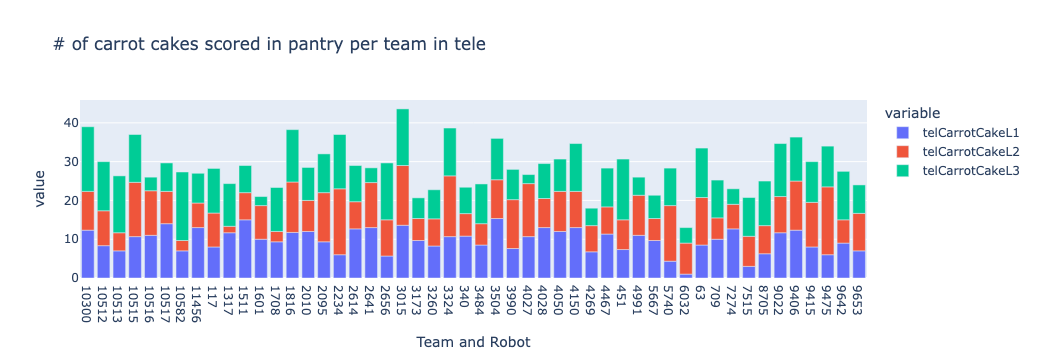

In [11]:
#L1, L2, L3 pantry carrot cake tele (stacked bar)
fig = px.bar(team_averages, x="Team and Robot", y=["telCarrotCakeL1", "telCarrotCakeL2", "telCarrotCakeL3"], title="# of carrot cakes scored in pantry per team in tele")
fig

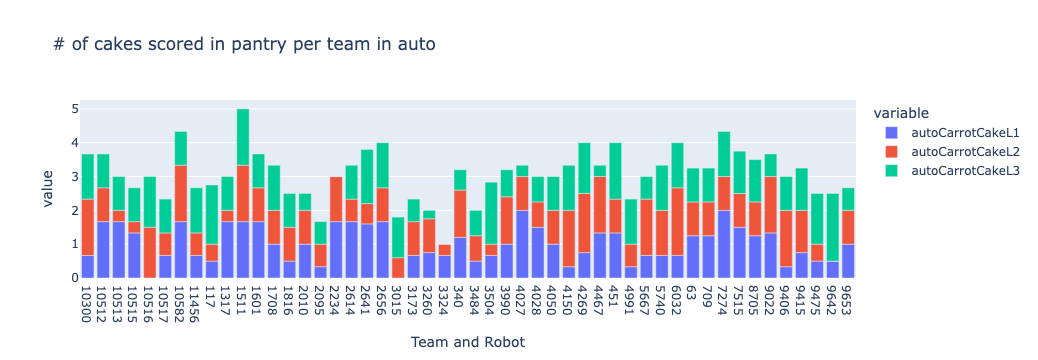

In [6]:
#L1, L2, L3 pantry carrot cake auto (stacked bar)
fig = px.bar(team_averages, x="Team and Robot", y=["autoCarrotCakeL1", "autoCarrotCakeL2", "autoCarrotCakeL3"], title="# of cakes scored in pantry per team in auto")
fig

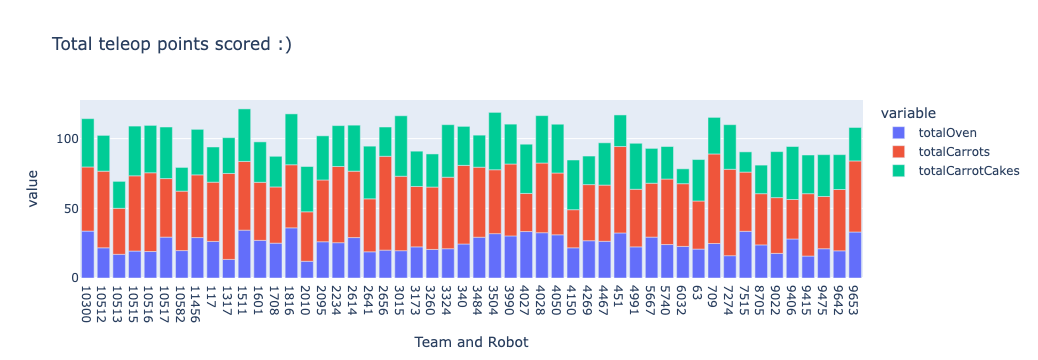

In [35]:
#total tele op points scored
team_averages["totalOven"] = team_averages["telCarrotO"] + team_averages["telCarrotCakeO"] 
team_averages["totalCarrots"] = team_averages["telCarrotL1"] + team_averages["telCarrotL2"] + team_averages["telCarrotL3"] + team_averages["Harvest Haul Carrots"]
team_averages["totalCarrotCakes"] = team_averages["telCarrotCakeL1"] + team_averages["telCarrotCakeL2"] + team_averages["telCarrotCakeL1"] + team_averages["Harvest Haul Carrot Cakes"]

fig = px.bar(team_averages, x="Team and Robot", y= ["totalOven", "totalCarrots", "totalCarrotCakes"], title = "Total teleop points scored :)")
fig.show()



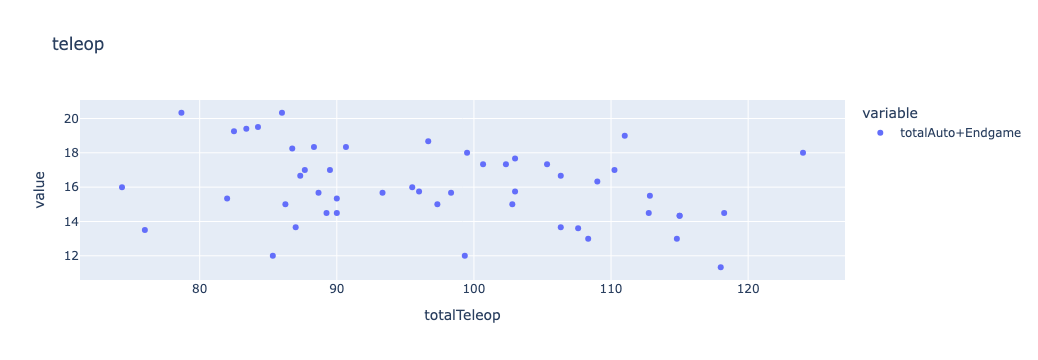

In [30]:
#heat map (tele op -x, endgame + auto -y)
team_averages["totalTeleop"] = team_averages["telCarrotO"] + team_averages["telCarrotCakeO"] + team_averages["telCarrotL1"] +  team_averages["telCarrotL2"] + team_averages["telCarrotL3"] + team_averages["telCarrotCakeL1"] + team_averages["telCarrotCakeL2"] + team_averages["telCarrotCakeL3"] 
team_averages["totalAuto"] = team_averages["autoCarrotO"] + team_averages["autoCarrotCakeO"] + team_averages["autoCarrotL1"] + team_averages["autoCarrotL2"] +  team_averages["autoCarrotL3"] + team_averages["autoCarrotCakeL1"] +  team_averages["autoCarrotCakeL2"] +  team_averages["autoCarrotCakeL3"]
team_averages["totalEndgame"] =  team_averages["Harvest Haul Carrots"] + team_averages["Harvest Haul Carrot Cakes"]
team_averages["totalAuto+Endgame"] = team_averages["totalEndgame"] + team_averages["totalAuto"]

fig = px.bar(team_averages, x="totalTeleop", y= ["totalAuto+Endgame"], title = "teleop")
fig.show()

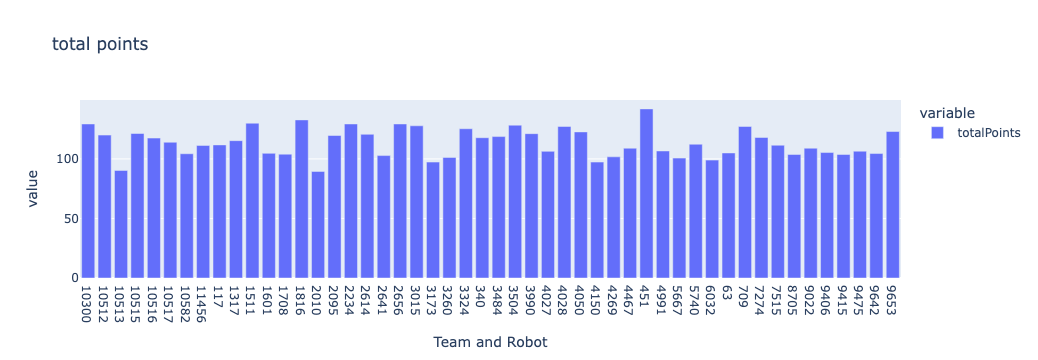

In [36]:
#total points scored
team_averages["totalPoints"] = team_averages["totalEndgame"] + team_averages["totalAuto"] + team_averages["totalTeleop"]

fig = px.bar(team_averages, x="Team and Robot", y= ["totalPoints"], title = "total points")
fig.show()